# Serie II · Fábrica — 08. Sensor virtual del flujo de vapor

**Pregunta 3 de la prueba:** construir un modelo que estime el flujo de vapor principal (`ZZQBCHLL`) a partir de las
demás variables; determinar qué variables y con qué rezago lo explican, y justificar la validación considerando que
son series de tiempo.

**Para qué sirve un sensor virtual.**
- Respaldo cuando el medidor de flujo falla o se calibra.
- Verificación continua del medidor: si medido y estimado se separan, algo está mal (pregunta 4).
- Una cifra de vapor confiable para calcular eficiencia (pregunta 5).

**Lo que dejó la pregunta 1:**
- `ZZQBCHLL` se actualiza cada 10 s y es un valor calculado (compensado por presión y temperatura).
- Se modela con **promedios de 1 minuto**, que es la escala útil para operación y elimina el escalonado de 10 s.
- Fuera de los modelos quedan `SXLTCYZ` y `YFJ3_ZD2`. Las seis presiones de hogar entran como su mediana y los pares
  izquierda-derecha como su promedio.
- **Nunca se usa el propio flujo de vapor rezagado:** el sensor virtual tiene que funcionar cuando el medidor no está.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold
warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from fabrica_datos import cargar, SENSORES
from fabrica_sensor_virtual import (OBJETIVO, PRESIONES_VAPOR, REZAGOS, VENTANA_MEDIA, tabla_minuto, con_rezagos,
                                    pliegues_adelante, ridge, hidraulico, metricas, bootstrap_bloques)

RAW = ROOT / "data" / "raw" / "serie2"
FIG = ROOT / "outputs" / "figures"; TAB = ROOT / "outputs" / "tables"; MOD = ROOT / "outputs" / "models"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9993"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
})
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG / nombre, bbox_inches="tight"); plt.show()
SEED = 20261019

DF = cargar(RAW / "data.csv")
T = tabla_minuto(DF)
Y_TODO = T[OBJETIVO]
NOMBRE = {c: SENSORES[c][0] for c in SENSORES} | {"presion_hogar": "Presión de hogar (mediana de 6)", "lecho": "Diferencial del lecho (promedio)",
          "o2": "O₂ en gases (promedio)", "t_gases": "Temperatura de gases (promedio)", "raiz_dp_rho": "√(ΔP·ρ) del sobrecalentador",
          "dp_sobrecalentador": "ΔP domo − colector", "retorno_total": "Aire a las cámaras de retorno (total)"}
print(f"Minutos: {len(T):,} | vapor: media {Y_TODO.mean():.1f} t/h, desvío {Y_TODO.std():.2f} t/h, rango {Y_TODO.min():.1f}-{Y_TODO.max():.1f} t/h")

Minutos: 7,201 | vapor: media 59.8 t/h, desvío 2.36 t/h, rango 51.5-70.6 t/h


## 1. Qué debería explicar el flujo de vapor

Tres mecanismos físicos, cada uno con su escala de tiempo:
1. **Hidráulico (instantáneo).** El vapor sale del domo, pasa por los sobrecalentadores y llega al colector. Por el
   roce pierde presión, y la pérdida crece con el flujo, como en una placa de orificio: Q ∝ √(ΔP·ρ). Aquí ΔP es la
   presión del domo menos la del colector, y ρ la densidad del vapor (∝ P/T).
2. **Energético (segundos a minutos).** Más carbón y aire liberan más calor, el hogar se calienta y se produce más
   vapor. Lo reflejan la temperatura del hogar, los flujos de aire y la corriente del tiro inducido.
3. **Másico (instantáneo).** El agua de atemperación se inyecta en el vapor y suma a su flujo.

ΔP domo − colector: media 0.326 MPa, rango 0.247-0.444 MPa (1 min)
  r con el vapor (1 min): ΔP domo − colector                            +0.974
  r con el vapor (1 min): √(ΔP·ρ) del sobrecalentador                   +0.985
  r con el vapor (1 min): Temperatura del hogar, parte superior (der.)  +0.877
  r con el vapor (1 min): Corriente del motor del ventilador de tiro inducido +0.818
  r con el vapor (1 min): Flujo de aire secundario                      +0.734
  r con el vapor (1 min): Flujo de agua de atemperación primaria        +0.667


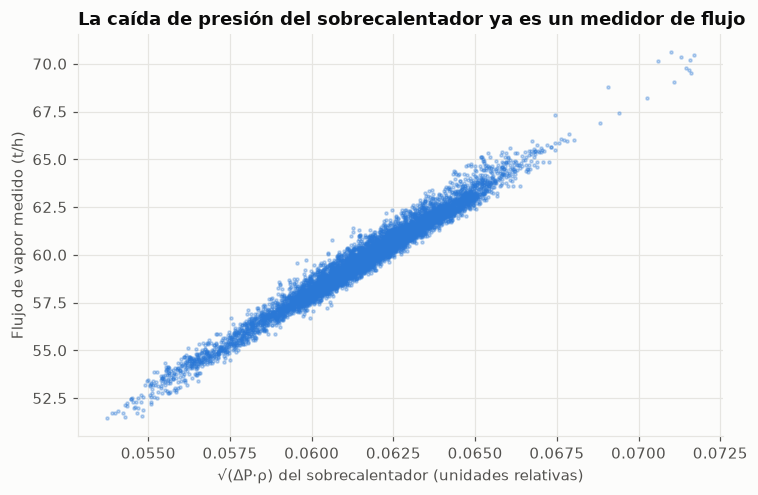

In [2]:
dp = T["dp_sobrecalentador"]
print(f"ΔP domo − colector: media {dp.mean():.3f} MPa, rango {dp.min():.3f}-{dp.max():.3f} MPa (1 min)")
for col in ["dp_sobrecalentador", "raiz_dp_rho", "TE_8313B", "YFJ3_AI", "FT_8302", "YJJWSLL"]:
    print(f"  r con el vapor (1 min): {NOMBRE[col]:45s} {T[col].corr(Y_TODO):+.3f}")
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.scatter(T["raiz_dp_rho"], Y_TODO, s=4, color=AZUL, alpha=0.3)
ax.set_xlabel("√(ΔP·ρ) del sobrecalentador (unidades relativas)"); ax.set_ylabel("Flujo de vapor medido (t/h)")
ax.set_title("La caída de presión del sobrecalentador ya es un medidor de flujo", loc="left")
guardar(fig, "serie2_10_hidraulico.png")

## 2. Con qué rezago se relaciona cada variable

Para ver quién adelanta a quién se correlacionan los **cambios** de 1 minuto (no los niveles: dos series con tendencia
se correlacionan aunque no tengan relación). Rezago positivo: la variable se mueve antes que el vapor.

,r nivel,rezago del pico (min),r de cambios en el pico,r de cambios a rezago 0
variable,,,,
Presión de vapor a la salida del colector,0.043,0,-0.277,-0.277
Presión del domo (izq.),0.351,1,0.237,-0.051
Temperatura de gases (promedio),0.563,-4,0.183,0.089
"Temperatura del hogar, parte superior (der.)",0.877,0,0.138,0.138
Temperatura del aire primario a la salida del precalentador,0.443,-8,0.135,0.003
Apertura de la válvula del atemperador primario,0.654,0,0.127,0.127
Temperatura del vapor a la salida de la caldera,0.169,1,0.119,0.102
O₂ en gases (promedio),-0.216,0,-0.118,-0.118
Corriente del motor del ventilador de tiro inducido,0.818,1,0.114,0.070


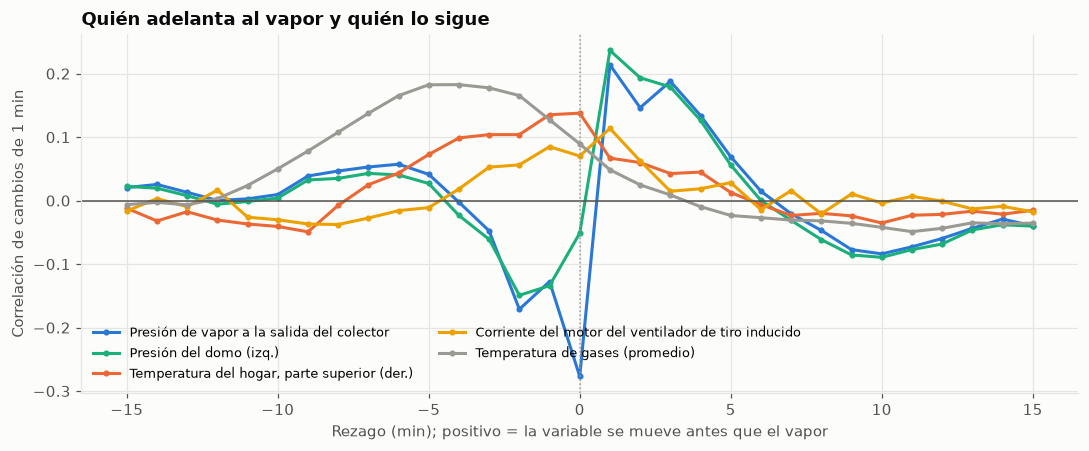

In [3]:
dy = Y_TODO.diff()
candidatas = ["PTCA_8324", "PTCA_8322A", "TE_8313B", "YFJ3_AI", "FT_8302", "FT_8301", "YJJWSLL", "TV_8329ZC", "o2",
              "t_gases", "TE_8303", "TE_8332A", "presion_hogar", "lecho"]
filas, CC = [], {}
for c in candidatas:
    dx = T[c].diff()
    s = pd.Series({L: dx.corr(dy.shift(-L)) for L in range(-15, 16)}); CC[c] = s
    Lb = int(s.abs().idxmax())
    filas.append({"variable": NOMBRE[c], "r nivel": T[c].corr(Y_TODO), "rezago del pico (min)": Lb, "r de cambios en el pico": s[Lb],
                  "r de cambios a rezago 0": s[0]})
REZ = pd.DataFrame(filas).set_index("variable").sort_values("r de cambios en el pico", key=abs, ascending=False)
display(REZ.round(3))

fig, ax = plt.subplots(figsize=(10, 4.2))
for c, color in zip(["PTCA_8324", "PTCA_8322A", "TE_8313B", "YFJ3_AI", "t_gases"], [AZUL, AQUA, NARANJA, AMARILLO, GRIS]):
    ax.plot(CC[c].index, CC[c], color=color, label=NOMBRE[c], marker="o", ms=3)
ax.axhline(0, color=TINTA2, lw=1); ax.axvline(0, color=GRIS, ls=":", lw=1)
ax.set_xlabel("Rezago (min); positivo = la variable se mueve antes que el vapor"); ax.set_ylabel("Correlación de cambios de 1 min")
ax.set_title("Quién adelanta al vapor y quién lo sigue", loc="left"); ax.legend(frameon=False, fontsize=8.5, ncol=2)
guardar(fig, "serie2_11_rezagos.png")

**Lectura de los rezagos:**
- **Presión del colector, en el mismo minuto (r ≈ −0.28).** Cuando la planta pide más vapor, sale más y la presión del
  colector cae al instante. Es la señal hidráulica.
- **Presión del domo y corriente del tiro inducido, ~1 minuto antes.** El fuego sube, el domo gana presión y el
  vapor sale después.
- **Temperatura del hogar, en el mismo minuto.**
- **Temperaturas de gases y del aire precalentado, 4-8 minutos después.** Son consecuencia del vapor, no causa:
  sirven para describir, no para estimar en tiempo real.
- **Las correlaciones de cambios son bajas (|r| < 0.3)** porque a 1 min el flujo tiene mucho ruido. La relación fuerte
  está en los niveles.

**Decisión:** el modelo usa el valor actual de cada variable, sus rezagos de 1, 2 y 5 min y su media de los últimos 10
min. Solo pasado y presente: nada del futuro.

## 3. Validación y modelos

**Validación hacia adelante por día.** Se entrena con todos los días anteriores y se predice el día siguiente
completo (4 pliegues: días 2 a 5). Se dejan **30 min de separación** entre entrenamiento y prueba, para que los
minutos vecinos, casi iguales, no filtren información. Así se usaría en la planta: se ajusta con el pasado y se
aplica hacia adelante.

**Modelos, de más simple a más complejo:**

| Modelo | Variables | Para qué |
|---|---|---|
| Media | ninguna | piso de comparación |
| Hidráulico | √(ΔP·ρ), una sola | física pura, dos parámetros |
| Ridge de combustión | sin presiones de vapor, con rezagos | respaldo si fallan las presiones; responde qué explica el fuego |
| Ridge completo | todas, con rezagos | el mejor lineal e interpretable |
| Gradient boosting | todas, con rezagos | ¿hay no linealidades que valga la pena capturar? |

In [4]:
todas = [c for c in T.columns if c not in (OBJETIVO, "dp_sobrecalentador")]
combustion = [c for c in todas if c not in PRESIONES_VAPOR + ["TE_8332A", "raiz_dp_rho"]]
FA = con_rezagos(T, todas); FC = con_rezagos(T, combustion); FH = T[["raiz_dp_rho"]]
ok = FA.notna().all(axis=1) & Y_TODO.notna()
IDX = Y_TODO[ok].index; Y = Y_TODO[ok]
gbm = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=40, random_state=0)
ESPEC = {"Media": None, "Hidráulico √(ΔP·ρ)": (hidraulico, FH), "Ridge de combustión": (ridge, FC),
         "Ridge completo": (ridge, FA), "Gradient boosting": (gbm, FA)}
PLIEGUES = pliegues_adelante(IDX, "30min")
PRED = {k: pd.Series(np.nan, index=IDX) for k in ESPEC}
for tr, te in PLIEGUES:
    for k, s in ESPEC.items():
        if s is None:
            PRED[k][te] = Y[tr].mean(); continue
        f, F = s; F = F.loc[IDX]
        PRED[k][te] = f().fit(F[tr], Y[tr]).predict(F[te])
MET = pd.DataFrame({k: metricas(Y, PRED[k]) for k in ESPEC}).T
display(MET.round(3))
dia = PRED["Media"].dropna().index.floor("D")
print("MAE por día de prueba (t/h):")
display(pd.DataFrame({k: (PRED[k] - Y).dropna().abs().groupby(dia).mean() for k in ESPEC}).round(3))

,MAE_t_h,MAPE_%,RMSE_t_h,R2,filas
Media,1.988,3.347,2.549,-0.026,5752.0
Hidráulico √(ΔP·ρ),0.328,0.546,0.436,0.970,5752.0
Ridge de combustión,0.688,1.148,0.867,0.881,5752.0
Ridge completo,0.179,0.301,0.224,0.992,5752.0
Gradient boosting,0.284,0.479,0.474,0.965,5752.0


MAE por día de prueba (t/h):


,Media,Hidráulico √(ΔP·ρ),Ridge de combustión,Ridge completo,Gradient boosting
date,,,,,
2022-03-28,1.917,0.307,0.741,0.217,0.440
2022-03-29,1.554,0.370,0.781,0.194,0.281
2022-03-30,2.485,0.441,0.728,0.194,0.361
2022-03-31,2.088,0.227,0.621,0.169,0.219
2022-04-01,1.765,0.249,0.540,0.121,0.167


In [5]:
E = {k: (PRED[k] - Y).dropna() for k in ESPEC}
comparaciones = [("Ridge completo", "Hidráulico √(ΔP·ρ)"), ("Ridge completo", "Gradient boosting"),
                 ("Ridge de combustión", "Gradient boosting"), ("Hidráulico √(ΔP·ρ)", "Ridge de combustión")]
CMP = pd.DataFrame([{"modelo A": a, "modelo B": b, **bootstrap_bloques(E[a], E[b], "1h", 2000, SEED)} for a, b in comparaciones])
CMP["IC90"] = CMP["ic90"].apply(lambda t: f"{t[0]:+.3f} a {t[1]:+.3f}")
print("Diferencia de MAE (A − B, t/h); negativo = A mejor. Bootstrap por bloques de 1 hora:")
display(CMP[["modelo A", "modelo B", "dif_MAE", "IC90", "P_a_peor"]].round(3))

Diferencia de MAE (A − B, t/h); negativo = A mejor. Bootstrap por bloques de 1 hora:


,modelo A,modelo B,dif_MAE,IC90,P_a_peor
0,Ridge completo,Hidráulico √(ΔP·ρ),-0.149,-0.185 a -0.117,0.0
1,Ridge completo,Gradient boosting,-0.105,-0.145 a -0.068,0.0
2,Ridge de combustión,Gradient boosting,0.403,+0.362 a +0.446,1.0
3,Hidráulico √(ΔP·ρ),Ridge de combustión,-0.360,-0.401 a -0.319,0.0


**Lectura:**
- **La física gana casi todo.** Una sola variable, la caída de presión del sobrecalentador, estima el vapor con
  ~0.33 t/h de error típico (0.5 %) y R² = 0.97. Contra eso, la media de los días anteriores se equivoca ~2 t/h.
- **El Ridge completo mejora un poco más:** ~0.18 t/h (0.30 %), R² = 0.99, y la diferencia con el hidráulico es
  significativa. Lo extra lo aporta sobre todo el agua de atemperación (sección 4).
- **Sin presiones de vapor, el error se multiplica por ~4** (~0.69 t/h, 1.1 %; R² = 0.88). Las variables del fuego explican el
  vapor, pero con el ruido propio de la combustión.
- **El gradient boosting no mejora al lineal; es peor** (~0.28 t/h, al nivel del modelo hidráulico de una variable),
  aunque recibe la misma variable física. Los árboles aproximan una recta con escalones y no extrapolan fuera del
  rango de entrenamiento. Aquí la relación es lineal en la variable física correcta, y el modelo simple gana.

## 4. Qué variables explican el vapor

Con variables tan correlacionadas entre sí, los coeficientes se reparten y quitar una sola casi no cambia nada (otra la
reemplaza). Por eso se responde por **mecanismo físico** y con modelos anidados, todos validados igual (hacia adelante
por día).

### 4.1 Con presiones de vapor: la física en dos variables

In [6]:
from sklearn.linear_model import LinearRegression
def mae_adelante(F, fabrica=ridge):
    F = F.loc[IDX]; pr = pd.Series(np.nan, index=IDX)
    for tr, te in PLIEGUES:
        pr[te] = fabrica().fit(F[tr], Y[tr]).predict(F[te])
    return (pr - Y).dropna().abs().mean()

ANID = pd.Series({
    "√(ΔP·ρ)": mae_adelante(T[["raiz_dp_rho"]], LinearRegression),
    "√(ΔP·ρ) + agua de atemperación": mae_adelante(T[["raiz_dp_rho", "YJJWSLL"]], LinearRegression),
    "√(ΔP·ρ) + agua + temperatura del vapor": mae_adelante(T[["raiz_dp_rho", "YJJWSLL", "TE_8332A"]], LinearRegression),
    "Ridge completo (todas, con rezagos)": MET.at["Ridge completo", "MAE_t_h"]})
display(ANID.round(3).to_frame("MAE hacia adelante (t/h)"))
dos = LinearRegression().fit(T.loc[IDX, ["raiz_dp_rho", "YJJWSLL"]], Y)
print(f"Modelo de dos variables (5 días): Q = {dos.intercept_:.2f} + {dos.coef_[0]:.1f}·√(ΔP·ρ) + {dos.coef_[1]:.2f}·agua")

,MAE hacia adelante (t/h)
√(ΔP·ρ),0.328
√(ΔP·ρ) + agua de atemperación,0.226
√(ΔP·ρ) + agua + temperatura del vapor,0.223
"Ridge completo (todas, con rezagos)",0.179


Modelo de dos variables (5 días): Q = -2.14 + 952.3·√(ΔP·ρ) + 1.18·agua


**Lectura.** Dos variables físicas hacen casi todo el trabajo:
- **La caída de presión del sobrecalentador** (forma de placa de orificio).
- **El agua de atemperación**, que se inyecta en el vapor y suma a su flujo. Su coeficiente es cercano a 1 t/h por
  t/h, como manda el balance de masa.

Con esas dos el error baja de 0.33 a ~0.23 t/h. Todo lo demás junto (rezagos, temperaturas, aire) aporta ~0.05 t/h
más.

### 4.2 Sin presiones de vapor: qué parte del fuego explica el vapor

,MAE solo con este grupo,aumento del MAE al quitarlo
Fuego y temperaturas,0.895,0.097
Aire y tiro,0.861,0.165
Atemperación,1.546,0.081
Lecho,1.910,-0.021


Ridge de combustión según los rezagos que usa (MAE hacia adelante, t/h):


,MAE
solo el valor actual,0.751
actual + 1 y 2 min,0.674
"actual + 1, 2 y 5 min",0.678
"actual + 1, 2, 5 min + media 10 min (el modelo)",0.688


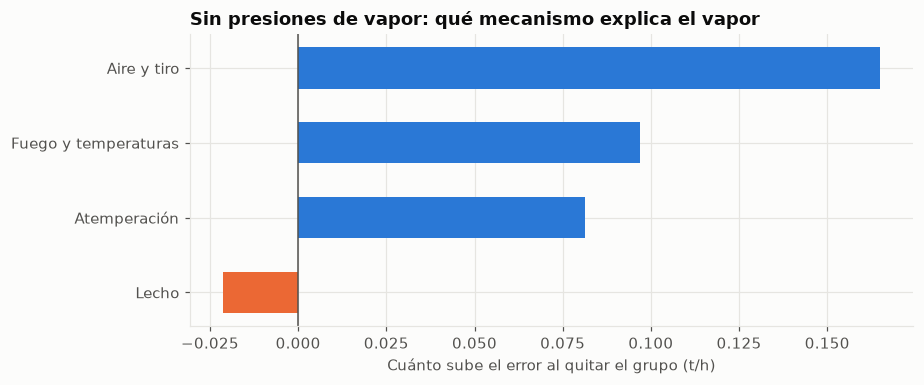

In [7]:
GRUPOS = {"Fuego y temperaturas": ["TE_8313B", "t_gases", "TE_8303", "TE_8304"],
          "Aire y tiro": ["FT_8301", "FT_8302", "retorno_total", "YFJ3_AI", "YFJ3_ZD1", "o2", "presion_hogar"],
          "Atemperación": ["YJJWSLL", "TV_8329ZC"], "Lecho": ["lecho", "SXLTCYY"]}
assert sorted(sum(GRUPOS.values(), [])) == sorted(combustion)
base_c = MET.at["Ridge de combustión", "MAE_t_h"]
MEC = pd.DataFrame({g: {"MAE solo con este grupo": mae_adelante(con_rezagos(T, cols)),
                        "aumento del MAE al quitarlo": mae_adelante(con_rezagos(T, [c for c in combustion if c not in cols])) - base_c}
                    for g, cols in GRUPOS.items()}).T
display(MEC.round(3))
REZ_AB = pd.Series({
    "solo el valor actual": mae_adelante(con_rezagos(T, combustion, rezagos=(0,), ventana=10).filter(like="|t-")),
    "actual + 1 y 2 min": mae_adelante(con_rezagos(T, combustion, rezagos=(0, 1, 2), ventana=10).filter(like="|t-")),
    "actual + 1, 2 y 5 min": mae_adelante(con_rezagos(T, combustion, rezagos=(0, 1, 2, 5), ventana=10).filter(like="|t-")),
    "actual + 1, 2, 5 min + media 10 min (el modelo)": base_c})
print("Ridge de combustión según los rezagos que usa (MAE hacia adelante, t/h):"); display(REZ_AB.round(3).to_frame("MAE"))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
v = MEC["aumento del MAE al quitarlo"].sort_values()
ax.barh(v.index, v.values, color=[NARANJA if x < 0 else AZUL for x in v.values], height=0.55)
ax.axvline(0, color=TINTA2, lw=1)
ax.set_xlabel("Cuánto sube el error al quitar el grupo (t/h)")
ax.set_title("Sin presiones de vapor: qué mecanismo explica el vapor", loc="left")
guardar(fig, "serie2_12_mecanismos.png")

**Lectura:**
- **Aire y tiro** es el grupo que más pesa: sin él, el error sube ~0.17 t/h. Le sigue el **fuego** (temperatura del
  hogar y de gases, ~0.10).
- **La atemperación** también aporta (~0.08), por el mismo balance de masa de la sección 4.1.
- **Cada grupo solo no alcanza:** aire y tiro 0.86 t/h, fuego 0.90, atemperación 1.55, lecho 1.91 (casi lo mismo que la
  media). El vapor se explica por la combinación:
  cuánto aire entra, cuánto calor hay en el hogar y cuánta agua se inyecta.
- **El lecho no ayuda;** quitarlo mejora un poco. Su ciclo de llenado y descarga no afecta la producción de vapor
  (pregunta 2).
- **Rezagos:** pasar del valor actual a incluir 1 y 2 min baja el error ~0.08 t/h. Más atrás (5 min, media de 10) no
  agrega. **La caldera responde en 1-2 minutos**, coherente con el análisis de correlaciones.

## 5. Banda de incertidumbre

Para cada día de prueba, la banda sale de los errores **fuera de muestra** de los días anteriores (cuantiles 5 % y
95 %). Así se calibraría en operación: con el desempeño real del modelo, no con el ajuste. El primer día de prueba no
tiene días previos evaluados y queda fuera.

In [8]:
filas = []
for k in ["Hidráulico √(ΔP·ρ)", "Ridge de combustión", "Ridge completo"]:
    e = E[k]; d = e.index.floor("D"); dias = sorted(d.unique())
    cub, anchos = [], []
    for i, dd in enumerate(dias[1:], start=1):
        prev = e[d < dd]; lo, hi = prev.quantile(0.05), prev.quantile(0.95)
        cur = e[d == dd]; cub.append(((cur >= lo) & (cur <= hi)).mean()); anchos.append(hi - lo)
    filas.append({"modelo": k, "cobertura (meta 90 %)": 100 * np.mean(cub), "ancho medio (t/h)": np.mean(anchos)})
BANDA = pd.DataFrame(filas).set_index("modelo"); display(BANDA.round(2))

,cobertura (meta 90 %),ancho medio (t/h)
modelo,,
Hidráulico √(ΔP·ρ),89.19,1.45
Ridge de combustión,90.40,2.69
Ridge completo,87.95,0.77


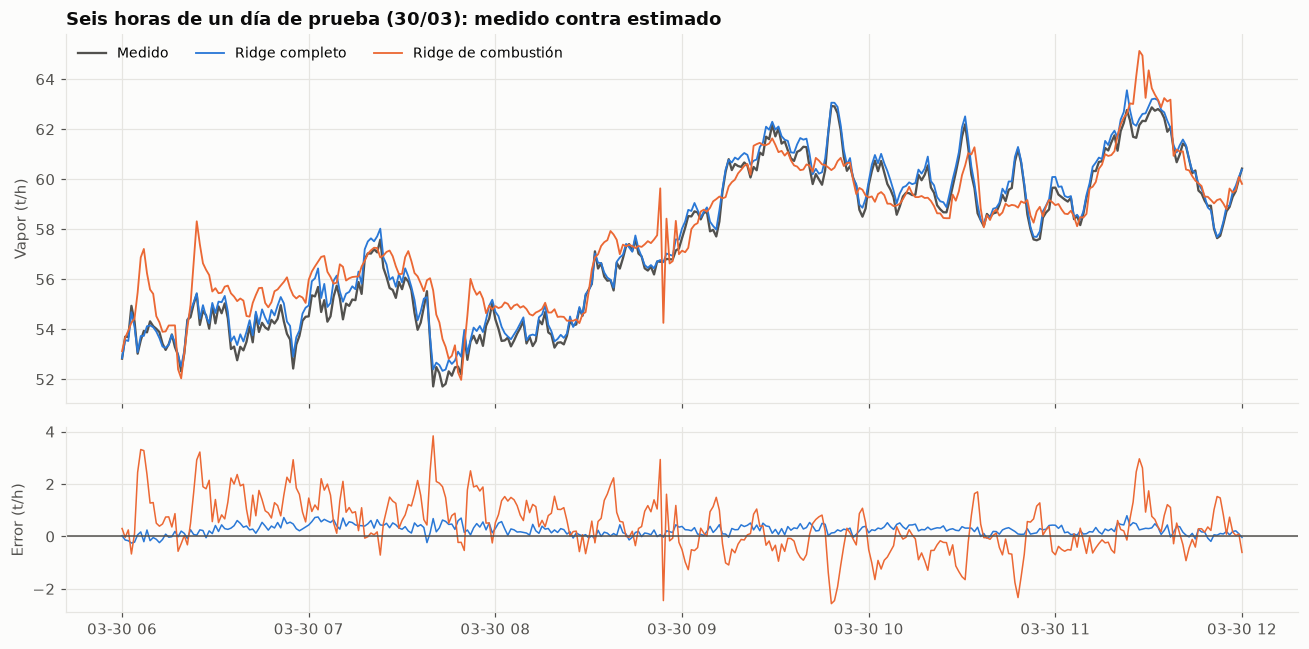

In [9]:
dia_ej = sorted(E["Ridge completo"].index.floor("D").unique())[2]
w = slice(dia_ej + pd.Timedelta("6h"), dia_ej + pd.Timedelta("12h"))
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axs[0].plot(Y.loc[w].index, Y.loc[w], color=TINTA2, lw=1.5, label="Medido")
axs[0].plot(PRED["Ridge completo"].loc[w].index, PRED["Ridge completo"].loc[w], color=AZUL, lw=1.2, label="Ridge completo")
axs[0].plot(PRED["Ridge de combustión"].loc[w].index, PRED["Ridge de combustión"].loc[w], color=NARANJA, lw=1.2, label="Ridge de combustión")
axs[0].set_ylabel("Vapor (t/h)"); axs[0].legend(frameon=False, fontsize=9, ncol=3, loc="upper left")
axs[0].set_title(f"Seis horas de un día de prueba ({dia_ej:%d/%m}): medido contra estimado", loc="left")
axs[1].plot(E["Ridge completo"].loc[w].index, E["Ridge completo"].loc[w], color=AZUL, lw=1, label="Ridge completo")
axs[1].plot(E["Ridge de combustión"].loc[w].index, E["Ridge de combustión"].loc[w], color=NARANJA, lw=1, label="Ridge de combustión")
axs[1].axhline(0, color=TINTA2, lw=1); axs[1].set_ylabel("Error (t/h)")
guardar(fig, "serie2_13_medido_vs_estimado.png")

## 6. Por qué no se valida con particiones al azar

Con particiones al azar (K-fold con mezcla), cada minuto de prueba tiene a sus vecinos, casi iguales, en el
entrenamiento. El modelo "recuerda" en vez de predecir.

In [10]:
kf = KFold(5, shuffle=True, random_state=0)
alazar = {}
for k in ["Ridge de combustión", "Ridge completo", "Gradient boosting"]:
    f, F = ESPEC[k]; F = F.loc[IDX]; pr = pd.Series(np.nan, index=IDX)
    for a, b in kf.split(F):
        pr.iloc[b] = f().fit(F.iloc[a], Y.iloc[a]).predict(F.iloc[b])
    alazar[k] = metricas(Y, pr)
AZ = pd.DataFrame({"MAE al azar": {k: v["MAE_t_h"] for k, v in alazar.items()},
                   "MAE hacia adelante": MET.loc[list(alazar), "MAE_t_h"]})
AZ["optimismo (%)"] = 100 * (1 - AZ["MAE al azar"] / AZ["MAE hacia adelante"])
display(AZ.round(3))

,MAE al azar,MAE hacia adelante,optimismo (%)
Ridge de combustión,0.569,0.688,17.252
Ridge completo,0.132,0.179,26.379
Gradient boosting,0.140,0.284,50.629


**Lectura.** Con particiones al azar el error parece entre 17 % y 51 % menor de lo que es. El más engañado es el
gradient boosting, que memoriza mejor a los vecinos: al azar casi empata con el Ridge (0.14 contra 0.13 t/h), cuando
hacia adelante es 60 % peor. Aquí el orden de los modelos no cambia, pero la validación al azar promete una precisión
que no existe.

## 7. Artefacto para la API y verificación

In [11]:
final = ridge().fit(FA.loc[IDX], Y)
hid = hidraulico().fit(FH.loc[IDX], Y)
sc, rg = final[0], final[-1]
e_cal = E["Ridge completo"]
artefacto = {
    "descripcion": "Serie II · sensor virtual del flujo de vapor (t/h), promedios de 1 min",
    "objetivo": OBJETIVO, "rezagos_min": list(REZAGOS), "ventana_media_min": VENTANA_MEDIA,
    "variables_base": todas, "variables_modelo": FA.columns.tolist(),
    "ridge": {"media": sc.mean_.tolist(), "escala": sc.scale_.tolist(), "coef": rg.coef_.tolist(),
              "intercepto": float(rg.intercept_), "alfa": float(rg.alpha_)},
    "hidraulico": {"formula": "Q = a + b*sqrt((P_domo - P_colector) * P_colector / (T_vapor + 273.15))",
                   "a": float(hid.intercept_), "b": float(hid.coef_[0])},
    "dos_variables": {"formula": "Q = a + b*sqrt(dP*rho) + c*agua_atemperacion", "a": float(dos.intercept_),
                      "b": float(dos.coef_[0]), "c": float(dos.coef_[1])},
    "banda_t_h": {"p05": float(e_cal.quantile(0.05)), "p95": float(e_cal.quantile(0.95))},
}
(MOD / "serie2_sensor_virtual.json").write_text(json.dumps(artefacto, ensure_ascii=False, indent=1), encoding="utf-8")
X = FA.loc[IDX].to_numpy()
p_json = ((X - np.array(artefacto["ridge"]["media"])) / np.array(artefacto["ridge"]["escala"])) @ np.array(artefacto["ridge"]["coef"]) + artefacto["ridge"]["intercepto"]
print(f"El JSON reproduce el Ridge final: diferencia máxima {np.abs(p_json - final.predict(FA.loc[IDX])).max():.2e} t/h en {len(X):,} minutos")
print(f"Fórmula hidráulica ajustada con los 5 días: Q = {hid.intercept_:.2f} + {hid.coef_[0]:.1f}·√(ΔP·ρ)")
res3 = {"metricas": MET.round(4).to_dict(orient="index"), "comparaciones": CMP.drop(columns=["ic90"]).round(4).to_dict(orient="records"),
        "banda": BANDA.round(3).to_dict(orient="index"), "al_azar": AZ.round(3).to_dict(orient="index"),
        "anidados": ANID.round(4).to_dict(), "mecanismos": MEC.round(4).to_dict(orient="index"), "rezagos_ablacion": REZ_AB.round(4).to_dict(),
        "rezagos": REZ.round(3).to_dict(orient="index"),
        "cc": {NOMBRE[c]: CC[c].round(3).tolist() for c in CC}, "cc_rezagos": list(range(-15, 16)),
        "hidraulico": {"a": float(hid.intercept_), "b": float(hid.coef_[0])},
        "dos_variables": {"a": float(dos.intercept_), "b": float(dos.coef_[0]), "c": float(dos.coef_[1])}}
(TAB / "serie2_resumen_p3.json").write_text(json.dumps(res3, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
pd.DataFrame({"medido": Y, **{k: PRED[k] for k in ESPEC}}).to_csv(TAB / "serie2_predicciones_p3.csv")

El JSON reproduce el Ridge final: diferencia máxima 0.00e+00 t/h en 7,182 minutos
Fórmula hidráulica ajustada con los 5 días: Q = -4.94 + 1051.0·√(ΔP·ρ)


In [12]:
# Muestra para las pruebas de la API (Serie IV): las últimas 3 h en promedios de 1 min, con lo que predice el Ridge
# final y los sensores crudos que usa la verificación de la pregunta 4. Con ella, tests/test_api_caldera_mercado.py comprueba
# que POST /caldera/vapor-virtual reproduce el modelo y que POST /caldera/verificar coincide con src/fabrica_anomalias.
VENT = T.index[-180:]
CRUDOS = ["PT_8313A", "PT_8313B", "PT_8313C", "PT_8313D", "PT_8313E", "PT_8313F", "AIR_8301A", "AIR_8301B", "ZCLCCY",
          "YCLCCY", "TE_8319A", "TE_8319B", "FT_8306A", "FT_8306B"]
M1 = DF.resample("1min").mean().interpolate(limit=3)          # igual que la verificación del notebook 09
muestra = T.loc[VENT, todas + [OBJETIVO]].join(M1.loc[VENT, CRUDOS])
completo = FA.loc[VENT].notna().all(axis=1)
muestra["pred_ridge"] = pd.Series(final.predict(FA.loc[VENT][completo]), index=VENT[completo])
muestra.round(6).to_csv(TAB / "serie2_muestra_api_vapor.csv")
print(f"Muestra para la API: {len(muestra)} minutos, {int(completo.sum())} con predicción del Ridge final")


Muestra para la API: 180 minutos, 180 con predicción del Ridge final


## Evaluación gerencial

**Qué significa para el ingenio.**
- La caldera ya trae un segundo medidor de vapor sin saberlo: la caída de presión entre el domo y el colector. Con
  ella sola, el vapor se estima con ~0.5 % de error.
- Sumando el agua de atemperación (balance de masa), el error baja a ~0.4 %. Con todas las variables, un modelo
  lineal llega a ~0.3 % (≈0.18 t/h), validado como se usaría: entrenando con el pasado y prediciendo días que no vio.
- Si fallan los transmisores de presión, el aire, el tiro y la temperatura del hogar dan un respaldo de ~1.1 %.

**Decisión recomendada.**
1. Poner en línea el **Ridge completo** como sensor virtual. El modelo de dos variables (presión y agua) sirve como
   verificación física, y el de combustión como respaldo.
2. Usar la diferencia medido − estimado como **alarma de deriva del medidor** (pregunta 4).
3. En las calderas de bagazo del ingenio, revisar primero si existen las dos presiones (domo y salida del
   sobrecalentador): con ellas se replica el sensor hidráulico casi sin modelar.

**Impacto estimado.**
- El chequeo con el modelo de dos variables detecta desvíos sostenidos del medidor desde ~1.3 t/h (~2 %). En la
  prueba de la pregunta 4, una deriva se detectó a las 1.7 h, con ~0.9 t/h de error.
- Evita operar a ciegas si el medidor sale de servicio.
- En plata depende de cuánto vapor se factura o se usa para calcular eficiencia: 1 % de error en 60 t/h son 0.6 t/h
  mal contadas, unas 14 t de vapor al día.

**Riesgos.**
- Cinco días con carga entre 51.5 y 70.6 t/h: fuera de ese rango (arranques, carga mínima) el modelo no está probado.
- El vapor "medido" ya es un cálculo compensado: el modelo aprende ese cálculo.
- Las presiones de vapor tienen resolución de 0.01 MPa: funcionan en promedios de 1 min, no a 5 s.
- Si las dos presiones fallan juntas (por ejemplo, la toma común), el modelo completo y el hidráulico caen a la vez.

**Nivel de certeza.**
- Alta en el ranking de modelos: 4 días de prueba hacia adelante, diferencias significativas por bootstrap de bloques.
- Alta en que la relación es física: tiene la forma correcta (r = 0.985). El intercepto (−4.9 t/h) indica que la recta
  vale en el rango observado (52-71 t/h), no para extrapolar a carga mínima.
- Media en la banda de incertidumbre: se calibra con 1 a 3 días previos y cubrió el 88 % (meta: 90 %).